# Initial Sales Exploration

This notebook explores the main sales patterns by date, store, and item.

In [1]:
from pathlib import Path

Path.cwd()

In [2]:
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "train.csv"

DATA_PATH

## Load the Dataset

In [3]:
import pandas as pd

sales = pd.read_csv(DATA_PATH, parse_dates=["date"])
sales.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


## Overall Sales Summary

In [4]:
overall_summary = pd.Series({
    "total_sales": sales["sales"].sum(),
    "average_sales_per_record": sales["sales"].mean(),
    "minimum_sales": sales["sales"].min(),
    "maximum_sales": sales["sales"].max(),
    "number_of_stores": sales["store"].nunique(),
    "number_of_items": sales["item"].nunique(),
})

overall_summary

total_sales                 4.770451e+07
average_sales_per_record    5.225029e+01
minimum_sales               0.000000e+00
maximum_sales               2.310000e+02
number_of_stores            1.000000e+01
number_of_items             5.000000e+01
dtype: float64

## Sales by Store

In [5]:
sales_bystore = (
    sales.groupby("store",as_index=False)["sales"]
    .sum()
    .sort_values("sales", ascending=False)
    .reset_index(drop=True)

)
sales_bystore

,store,sales
0,2,6120128
1,8,5856169
2,3,5435144
3,10,5360158
4,9,5025976
5,4,5012639
6,1,4315603
7,5,3631016
8,6,3627670
9,7,3320009


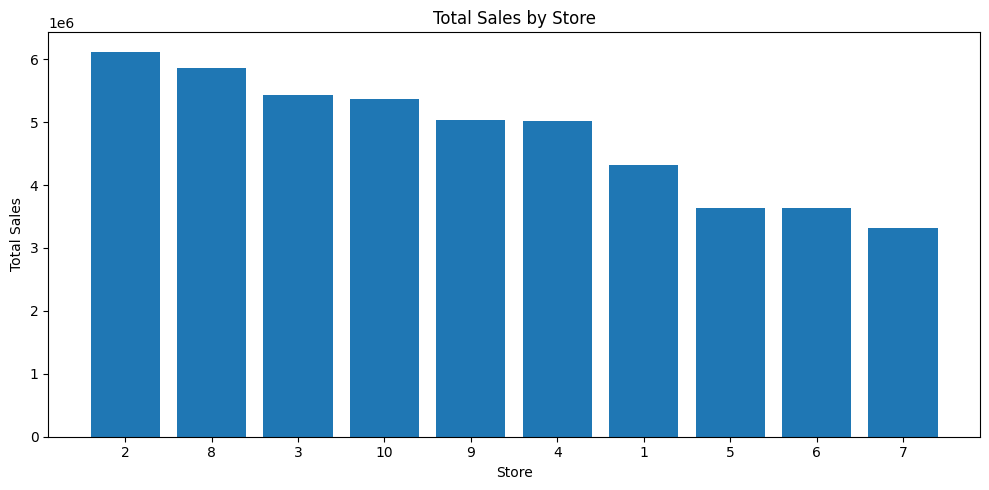

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10,5))

ax.bar(
    sales_bystore["store"].astype(str),
    sales_bystore["sales"]
)

ax.set_title("Total Sales by Store")
ax.set_xlabel("Store")
ax.set_ylabel("Total Sales")

plt.tight_layout()
plt.show()

### Observation

Store 2 records the highest total sales, while Store 7 records the lowest. These differences cannot be fully explained because the dataset does not include store size, location, prices, or promotions.

## Sales by Item

In [7]:
sales_by_item = (
    sales.groupby("item", as_index=False)["sales"]
    .sum()
    .sort_values("sales", ascending=False)
    .reset_index(drop=True)
)

top_10_items = sales_by_item.head(10)

top_10_items

,item,sales
0,15,1607442
1,28,1604713
2,13,1539621
3,18,1538876
4,25,1473334
5,45,1471467
6,38,1470330
7,22,1469971
8,36,1406548
9,8,1405108


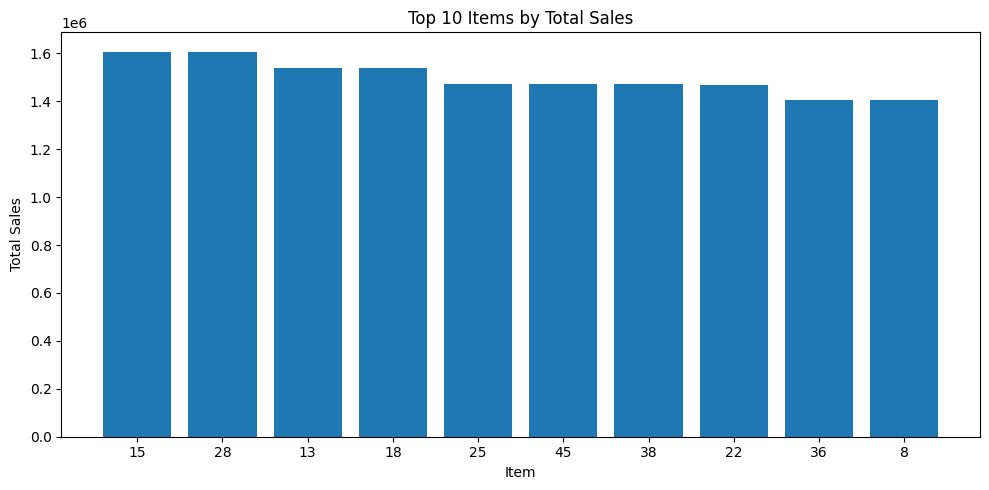

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    top_10_items["item"].astype(str),
    top_10_items["sales"]
)

ax.set_title("Top 10 Items by Total Sales")
ax.set_xlabel("Item")
ax.set_ylabel("Total Sales")

plt.tight_layout()
plt.show()

### Observation

Items 15 and 28 record the highest total sales. The leading items have relatively similar sales levels, but the available data does not provide product names, categories, prices, or promotions to explain these differences.

## Sales Over Time

In [9]:
daily_sales = (
    sales.groupby("date", as_index=False)["sales"]
    .sum()
    .sort_values("date")
)

daily_sales.head()

,date,sales
0,2013-01-01,13696
1,2013-01-02,13678
2,2013-01-03,14488
3,2013-01-04,15677
4,2013-01-05,16237


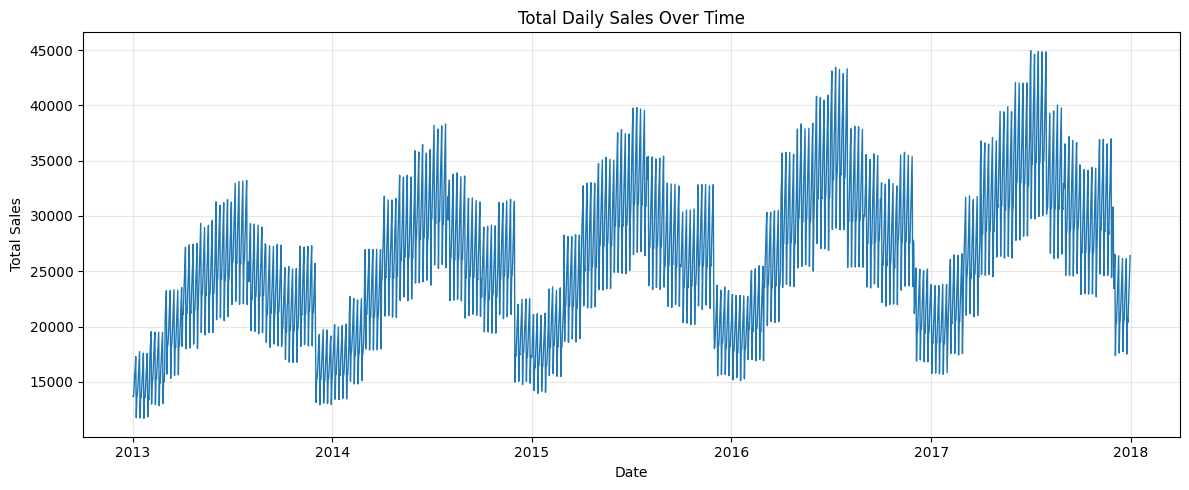

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    daily_sales["date"],
    daily_sales["sales"],
    linewidth=1,
)

ax.set_title("Total Daily Sales Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Total Sales")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Observation

Daily sales show an overall upward trend and a recurring annual pattern. Regular short-term fluctuations also suggest a weekly seasonal effect. These patterns describe observed sales, but the dataset does not contain inventory data to determine whether stockouts limited actual demand.

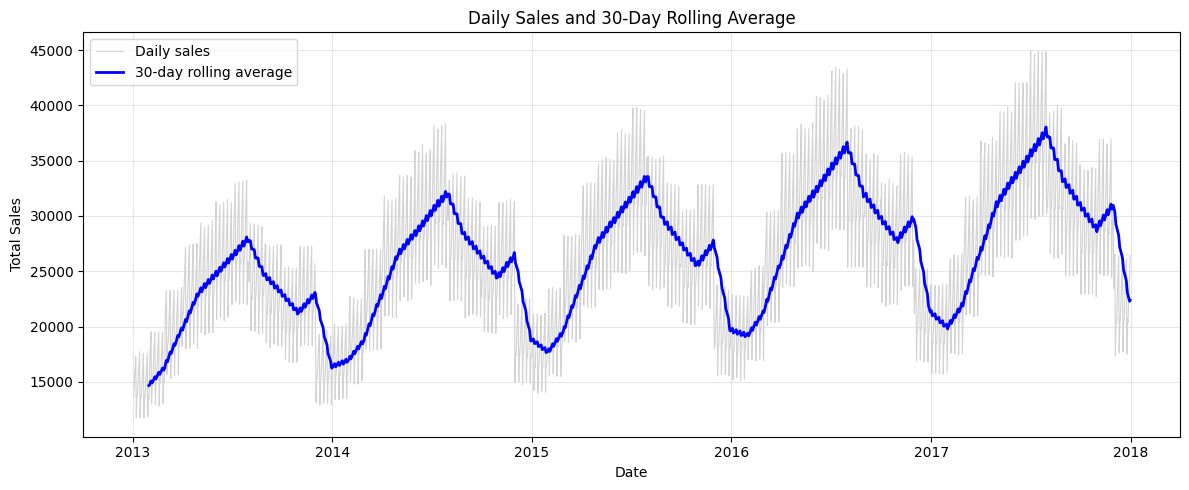

In [11]:
daily_sales["rolling_mean_30"] = (
    daily_sales["sales"]
    .rolling(window=30)
    .mean()
)

fig, ax =plt.subplots(figsize=(12,5))

ax.plot(
    daily_sales["date"],
    daily_sales["sales"],
    color="lightgray",
    linewidth=0.8,
    label="Daily sales",
)

ax.plot(
    daily_sales["date"],
    daily_sales["rolling_mean_30"],
    color="blue",
    linewidth=2,
    label="30-day rolling average",
)

ax.set_title("Daily Sales and 30-Day Rolling Average")
ax.set_xlabel("Date")
ax.set_ylabel("Total Sales")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

### Observation

The 30-day rolling average confirms a recurring annual seasonal cycle. Sales generally increase toward the middle of each year and decline afterward. Both seasonal peaks and lower periods appear to increase over time, suggesting an overall upward trend.

## Weekly Seasonality

In [12]:
daily_sales["day_of_week"] = daily_sales["date"].dt.day_name()

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

sales_by_weekday = (
    daily_sales.groupby("day_of_week")["sales"]
    .mean()
    .reindex(weekday_order)
    .reset_index()
)

sales_by_weekday

,day_of_week,sales
0,Monday,20714.819231
1,Tuesday,24112.954023
2,Wednesday,24184.252874
3,Thursday,25861.609195
4,Friday,27578.624521
5,Saturday,29331.348659
6,Sunday,31071.666667


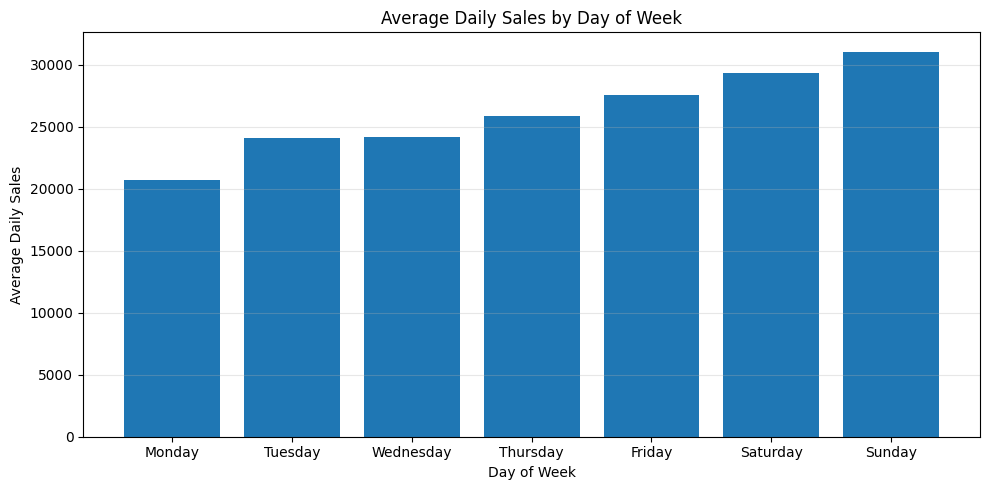

In [13]:
fig, ax = plt.subplots(figsize=(10,5))

ax.bar(
    sales_by_weekday["day_of_week"],
    sales_by_weekday["sales"],
)

ax.set_title("Average Daily Sales by Day of Week")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Average Daily Sales")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Observation

Average daily sales increase throughout the week. Monday records the lowest average, while Sunday records the highest. Sunday sales are approximately 50% higher than Monday sales, indicating a strong weekly seasonal pattern.

## Monthly Seasonality

In [14]:
daily_sales["month"] = daily_sales["date"].dt.month_name()

month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December",
]

sales_by_month = (
    daily_sales.groupby("month")["sales"]
    .mean()
    .reindex(month_order)
    .reset_index()
)

sales_by_month

,month,sales
0,January,17762.251613
1,February,19689.198582
2,March,23652.787097
3,April,27576.446667
4,May,29564.109677
5,June,31512.740000
6,July,33499.309677
7,August,29552.612903
8,September,27536.380000
9,October,25596.903226


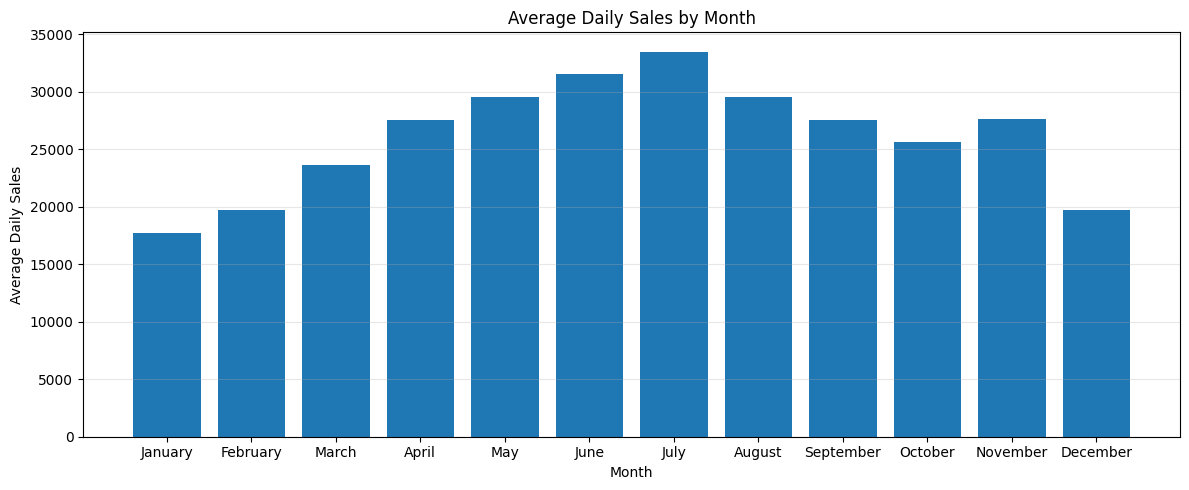

In [15]:
fig, ax= plt.subplots(figsize=(12,5))

ax.bar(
    sales_by_month["month"],
    sales_by_month["sales"]
)

ax.set_title("Average Daily Sales by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Average Daily Sales")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Observation

Average daily sales increase from January to July, which records the highest level. Sales then generally decline during the second half of the year, with a temporary increase in November and a sharp decrease in December. This recurring pattern confirms strong annual seasonality.

## Key Findings

- The dataset contains 913,000 daily sales records covering 10 stores and 50 items from 2013 to 2017.
- No missing values or duplicated rows were identified.
- Store 2 records the highest total sales, while Store 7 records the lowest.
- Items 15 and 28 record the highest total sales.
- Daily sales show an overall upward trend across the five-year period.
- Sales follow a strong weekly pattern, with the lowest average on Monday and the highest on Sunday.
- Sales also follow a strong annual pattern, increasing from January to July before generally declining during the second half of the year.

## Limitations

The dataset does not include prices, promotions, inventory levels, stockouts, product information, store characteristics, or supplier data. The analysis therefore identifies sales patterns but cannot explain their business causes. Observed sales may also differ from actual demand if historical stockouts occurred.

## Next Steps

The next phase will create a time-based training and test split, establish a simple forecasting baseline, and evaluate predictions using appropriate error metrics.